In [3]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
 ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) # must say cuda; if not, turn on the GPU
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
 n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
 n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
 print(f'{c:10s} train {n_tr:5d} test {n_te:4d}')


Device: cuda
buildings  train  2191 test  437
forest     train  2271 test  474
glacier    train  2404 test  553
mountain   train  2512 test  525
sea        train  2274 test  510
street     train  2382 test  501


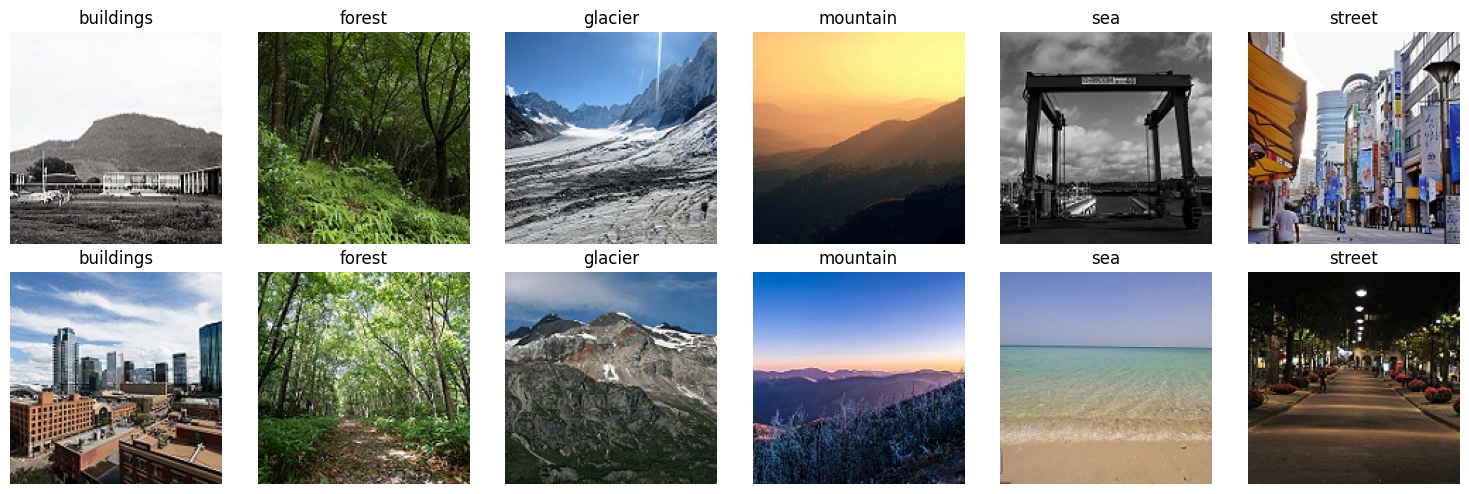

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
     files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
     for i, f in enumerate(files):
         img = Image.open(os.path.join(TRAIN_DIR, c, f))
         axes[i, j].imshow(img)
         axes[i, j].set_title(c)
         axes[i, j].axis('off')
plt.tight_layout()
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
 ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

# Part-1: Image Dataset Visualization and Pixel Analysis

The Intel Image Classification dataset contains six classes: buildings, forest, glacier, mountain, sea, and street. Sample images from each class were displayed to understand the visual differences between the categories.

Image Properties

* Image shape: 150 × 150 × 3
* Data type: uint8
* Pixel value range: 0 to 255
* Color channels: Red, Green, and Blue (RGB)

Pixel Analysis

The top-left (3 \times 3) region of the red channel was extracted from a sample image to examine its pixel values.

Conclusion

Visualizing sample images and examining pixel values helps us understand the dataset structure and how images are represented numerically before applying transfer learning with ResNet-18.

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


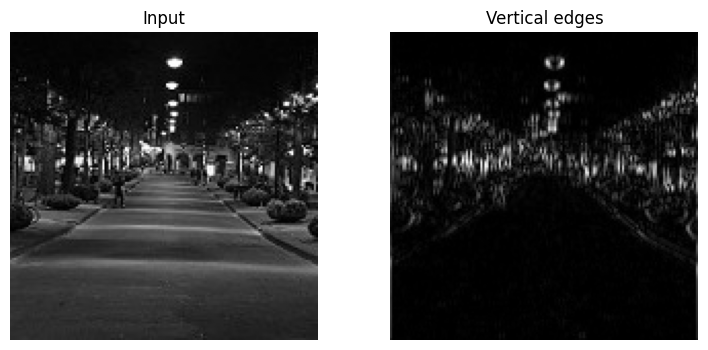

In [5]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze()) # expect three rows of [30, 30, 0]
# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
 a.axis('off')
plt.show()

In [6]:
def count(m):
 return sum(p.numel() for p in m.parameters())
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64 : {count(conv):,} parameters') # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')
t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
 c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
 print(f'stride {stride}: output {tuple(c(t).shape)}') # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))


Conv 3x3, 3 -> 64 : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


# Part-2:Convolution and Dense Layer Parameter Analysis

This experiment demonstrates how to calculate the number of trainable parameters in convolutional and fully connected layers. It also shows how stride affects the output dimensions of convolutional layers.

### Results

* 3 × 3 Convolution (3 input channels to 64 output channels): 1,792 parameters.
* Dense Layer (67,500 input features to 512 output features): 34,560,512 parameters.
* Convolution with stride 1: Output shape is (1, 64, 224, 224).
* Convolution with stride 2: Output shape is (1, 64, 112, 112).
* 2 × 2 Max Pooling: Output shape is (1, 3, 112, 112).

### Conclusion

Convolutional layers extract spatial features from images, while dense layers combine learned features for prediction. Increasing the stride reduces the spatial dimensions of the output, and max pooling downsamples feature maps.

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats
train_tf = transforms.Compose([
 transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
 transforms.RandomHorizontalFlip(),
 transforms.ColorJitter(brightness=0.2, contrast=0.2),
 transforms.ToTensor(),
 transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
 transforms.Resize((224, 224)),
 transforms.ToTensor(),
 transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


# Part-3:Data Augmentation and Dataset Preparation

This step prepares the Intel Image Classification dataset for training, validation, and testing using PyTorch.

### Data Preprocessing

* Training transformations: Random resized cropping, horizontal flipping, and color jittering are applied to improve data augmentation.
* Validation and testing transformations: Images are resized to 224 × 224 pixels and normalized using ImageNet mean and standard deviation values.
* Normalization: Pixel values are normalized to match the input requirements of the pretrained ResNet-18 model.

### Dataset Splitting

The dataset is divided into three subsets:

* Training set: 11,929 images
* Validation set: 2,105 images
* Testing set: 3,000 images

### Conclusion

Data augmentation helps improve model generalization, while separate validation and testing datasets support model evaluation. PyTorch DataLoaders efficiently load images in batches during training and evaluation.

In [8]:
def run_epoch(model, loader, optimizer=None):
 """One pass over the data. Trains only if an optimizer is given."""
 training = optimizer is not None
 model.train(training)
 total_loss, correct, n = 0.0, 0, 0
 with torch.set_grad_enabled(training):
   for xb, yb in loader:
     xb, yb = xb.to(device), yb.to(device)
     logits = model(xb) # forward pass
     loss = F.cross_entropy(logits, yb) # softmax + log loss
     if training:
       optimizer.zero_grad()
       loss.backward() # backpropagation
       optimizer.step() # gradient step
     total_loss += loss.item() * len(yb)
     correct += (logits.argmax(1) == yb).sum().item()
     n += len(yb)
 return total_loss / n, correct / n
    
def fit(model, optimizer, epochs, history):
 best_acc, best_state = -1.0, None
 for ep in range(epochs):
     t0 = time.time()
     tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
     va_loss, va_acc = run_epoch(model, val_dl)
     history.append((tr_loss, va_loss, tr_acc, va_acc))
     if va_acc > best_acc:
         best_acc = va_acc
         best_state = copy.deepcopy(model.state_dict())
     print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
         f'val loss {va_loss:.3f} acc {va_acc:.3f} '
         f'({time.time() - t0:.0f}s)')
 model.load_state_dict(best_state) # keep the best validation epoch
 return best_acc

In [9]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
 p.requires_grad = False # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes)) # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 213MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (72s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (35s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (35s)
Best validation accuracy, feature extraction: 0.901


# Part-4:Transfer Learning — Feature Extraction

In this step, a pretrained ResNet-18 model is used for the Intel Image Classification dataset. The pretrained model’s weights are loaded from ImageNet, and the convolutional layers are frozen to preserve the learned features.

The final fully connected layer is replaced with a new classification layer for the six image categories.

# Training Configuration

* Model: ResNet-18
* Approach: Transfer learning using feature extraction
* Trainable parameters: 3,078
* Total parameters: 11,179,590
* Optimizer: Adam
* Learning rate: 0.001
* Training epochs: 3

# Results

The model achieved a best validation accuracy of approximately 90.1% after three epochs.

Training loss decreased across the epochs, while validation accuracy improved, indicating that the pretrained model learned useful features for classifying the six categories in the Intel Image Classification dataset.


In [10]:
for p in model.layer4.parameters():
 p.requires_grad = True # unfreeze the last block
opt = torch.optim.Adam([
 {'params': model.layer4.parameters(), 'lr': 1e-4}, # gentle: pretrained
 {'params': model.fc.parameters(), 'lr': 1e-3}]) # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.226 acc 0.926 (35s)
epoch 2: train loss 0.170 acc 0.937 | val loss 0.204 acc 0.932 (36s)
epoch 3: train loss 0.124 acc 0.955 | val loss 0.220 acc 0.926 (35s)
Best validation accuracy, fine-tuned: 0.932


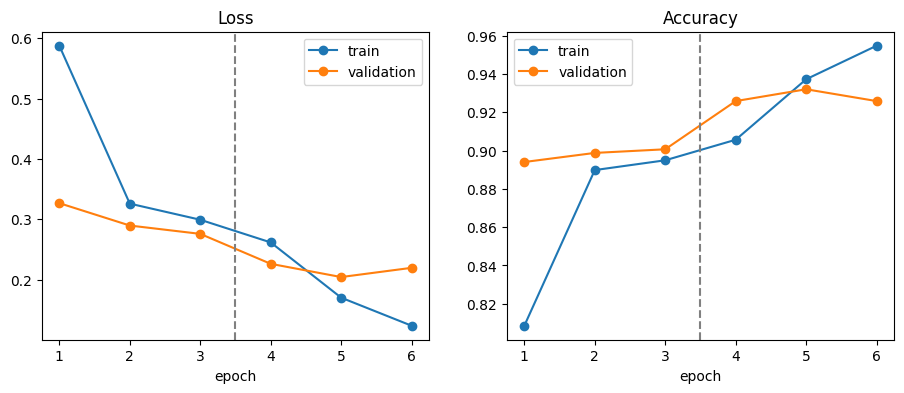

In [11]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
 a.axvline(3.5, color='gray', ls='--') # where fine-tuning starts
 a.set_title(title)
 a.set_xlabel('epoch')
 a.legend()
plt.show()


# Part 5: Fine-Tuning ResNet-18

In this step, the last convolutional block (layer4) of the pretrained ResNet-18 model is unfrozen for fine-tuning. This allows the model to adapt its pretrained features to the Intel Image Classification dataset.

The Adam optimizer uses different learning rates for the pretrained layer and the new classification layer.

### Fine-Tuning Configuration

* Model: ResNet-18
* Unfrozen layer: layer4
* Trainable parameters: 8,396,806
* Learning rate for layer4: 0.0001
* Learning rate for the classification layer: 0.001
* Fine-tuning epochs: 3

### Results

The model achieved a best validation accuracy of 93.2% during fine-tuning.

* Epoch 1 validation accuracy: 92.6%
* Epoch 2 validation accuracy: 93.2%
* Epoch 3 validation accuracy: 92.6%

The training loss decreased from 0.262 to 0.124. Fine-tuning improved the model’s best validation accuracy from 90.1% during feature extraction to 93.2%, showing that adapting the pretrained features helped classification performance.

### Learning Curves

The loss and accuracy graphs compare training and validation performance across all six epochs. The dashed vertical line marks where fine-tuning begins, after the first three feature-extraction epochs.

Test accuracy: 0.935
              precision    recall  f1-score   support

   buildings      0.954     0.899     0.926       437
      forest      0.994     0.985     0.989       474
     glacier      0.921     0.870     0.895       553
    mountain      0.885     0.920     0.902       525
         sea      0.945     0.980     0.962       510
      street      0.921     0.958     0.939       501

    accuracy                          0.935      3000
   macro avg      0.937     0.935     0.936      3000
weighted avg      0.935     0.935     0.934      3000



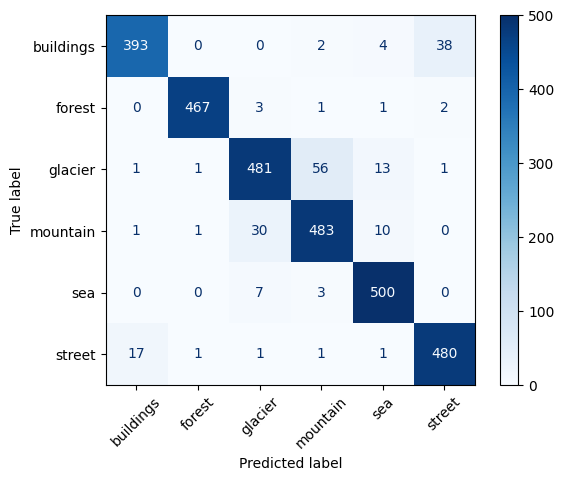

In [12]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
 for xb, yb in test_dl:
     p = F.softmax(model(xb.to(device)), dim=1).cpu()
     probs.append(p)
     preds.append(p.argmax(1))
     labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
 cmap='Blues', xticks_rotation=45)
plt.show()


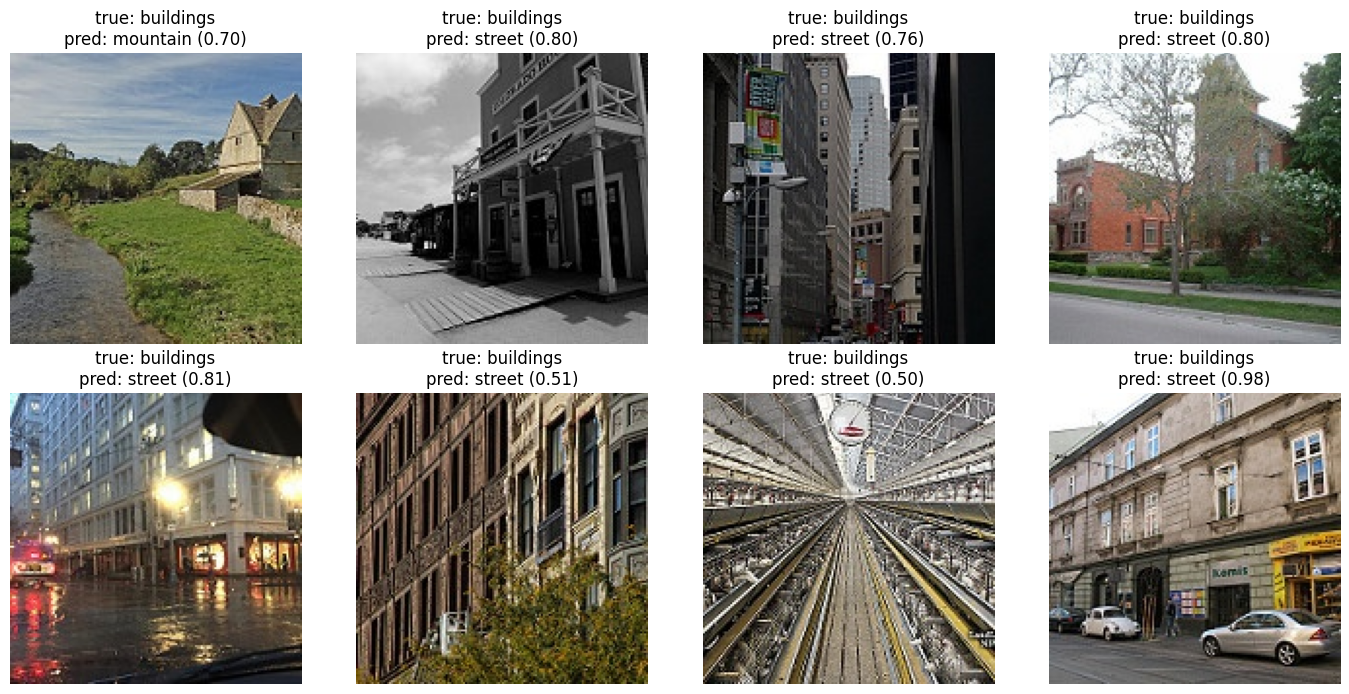

In [13]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
 ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
 path, _ = test_ds.samples[i]
 ax.imshow(Image.open(path))
 ax.set_title(f'true: {classes[labels[i]]}\n'
 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()


In [14]:
x0, y0 = test_ds[0]
with torch.no_grad():
 logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
 print(f'{c:10s} logit {z:6.2f} probability {q:.3f}')

True class: buildings
buildings  logit   7.93 probability 1.000
forest     logit  -9.37 probability 0.000
glacier    logit  -4.62 probability 0.000
mountain   logit  -4.99 probability 0.000
sea        logit  -4.58 probability 0.000
street     logit  -3.41 probability 0.000


# Part 6: Model Evaluation and Error Analysis

Test Set Evaluation

The fine-tuned ResNet-18 model was evaluated on the test dataset containing 3,000 images from six classes: buildings, forest, glacier, mountain, sea, and street.

### Test Results

* Test Accuracy: 93.5%
* Macro Average Precision: 93.7%
* Macro Average Recall: 93.5%
* Macro Average F1-score: 93.6%
* Weighted Average F1-score: 93.4%

### Classification Report Analysis

The forest class achieved the highest F1-score of 0.989, followed by sea with 0.962 and street with 0.939. The glacier class had an F1-score of 0.895, while mountain achieved 0.902 and buildings achieved 0.926.

### Confusion Matrix

The confusion matrix compares the actual labels with the model’s predicted labels. Most images were correctly classified, as shown by the high values along the diagonal.

Some glaciers were misclassified as mountains, and some buildings were predicted as streets. These errors suggest that visually similar features between classes can make classification difficult.

### Error Analysis

The model achieved strong overall performance, correctly classifying 93.5% of the test images. However, the misclassified examples show that the model can struggle when different classes share similar visual patterns.

Examining incorrect predictions helps identify weaknesses and provides opportunities for further model improvement.

In [15]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


# Saving the Trained Model

After training and fine-tuning the ResNet-18 model, the model’s learned parameters were saved to a file named resnet18_intel.pt.

The saved model file is approximately 44.8 MB in size and is stored at /kaggle/working/resnet18_intel.pt.

Saving the model allows its trained weights to be loaded later for image classification without repeating the entire training process.

# Conclusion

The ResNet-18 transfer learning model achieved 93.5% test accuracy on the Intel Image Classification dataset. Fine-tuning improved the model’s ability to classify six types of scenes. The results demonstrate that transfer learning can provide strong image classification performance while reducing the need to train a deep neural network from scratch.

# Check Your Understanding — Lab 5

### 1. Why does a network without nonlinear activations collapse to a single linear layer?

Without nonlinear activation functions, multiple linear layers can be combined into a single linear transformation. Therefore, the network cannot learn complex nonlinear patterns.

### 2. For logits [3, 1, 0], what probability does softmax give the first class?

Softmax formula:

P1 = exp(3) / (exp(3) + exp(1) + exp(0))

P1 = 20.086 / (20.086 + 2.718 + 1)

P1 = 20.086 / 23.804 = 0.844

Answer: Approximately 84.4%.

### 3. How many parameters does a 3 × 3 convolution from 64 to 128 channels have?

Parameters = (Kernel height × Kernel width × Input channels × Output channels) + Biases

Parameters = (3 × 3 × 64 × 128) + 128

Parameters = 73,728 + 128 = 73,856

Answer: 73,856 parameters, including biases.

### 4. An input of 56 × 56 goes through a 3 × 3 convolution with padding 1 and stride 2. What is the output size?

Output size = floor((Input size + 2 × Padding − Kernel size) / Stride) + 1

Output size = floor((56 + 2 × 1 − 3) / 2) + 1

Output size = floor(55 / 2) + 1 = 28

Answer: 28 × 28 per output channel.

### 5. Why does a residual (skip) connection help gradients reach the early layers?

A residual connection provides a shortcut for gradients to flow backward through the network. It helps reduce the vanishing-gradient problem and makes deep neural networks easier to train.

### 6. When would you train a CNN from scratch instead of using transfer learning?

Training a CNN from scratch may be appropriate when a very large labeled dataset is available, the task is very different from the pretrained model’s original task, or suitable pretrained weights are unavailable. Transfer learning is often more efficient when the dataset is smaller.